# 04 · Experiment B: does a second gas-sensor dataset (SmellNet) help coffee classification? (RQ3)

S1 (8 Figaro/FIS sensors, resistance) and S2 (6 Grove/MQ channels, raw readings) differ in sensors, units and channel count. **Harmonisation:** S1 → conductance (so both rise with gas), common length of 300 s, per-measurement z-score per channel. **Channel-agnostic models:** B1 uses one encoder shared by every channel, pooled across channels; B2 computes features per channel and aggregates them across channels (mean/std/max/min). Both are trained on 3 coffee + 50 SmellNet classes and evaluated **only on held-out S1 measurements** (argmax over the 3 coffee classes). B3 combines the S1-only model with the pooled model. S2 only ever enters training. Code: `src/experiments/expB_s1_s2.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
R = ROOT / 'results'; F = R / 'figures'; A = R / 'ablations'
def show(p, w=650):
    p = Path(p)
    display(Image(filename=str(p), width=w)) if p.exists() else print('missing figure:', p.name)
def table(p, **kw):
    p = Path(p)
    return pd.read_csv(p, **kw) if p.exists() else print('missing table:', p.name)

In [2]:
b = table(R / 'expB_s1_s2_fusion.csv')
b[['exp','level','variant','accuracy_mean','accuracy_std','balanced_accuracy_mean','macro_f1_mean']]

,exp,level,variant,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean
0,expB_b2,none (S1 only),S1only|LR,0.734,0.027,0.690,0.687
1,expB_b2,mid,B2|LR,0.612,0.033,0.600,0.583
2,expB_b2,high,B3|LR|mean,0.698,0.038,0.660,0.654
3,expB_b2,high,B3|LR|weighted,0.719,0.028,0.677,0.672
4,expB_b2,high,B3|LR|stacking,0.750,0.026,0.677,0.686
5,expB_b2,none (S1 only),S1only|RF,0.772,0.039,0.733,0.740
6,expB_b2,mid,B2|RF,0.721,0.023,0.695,0.691
7,expB_b2,high,B3|RF|mean,0.769,0.023,0.732,0.738
8,expB_b2,high,B3|RF|weighted,0.766,0.027,0.730,0.736
9,expB_b2,high,B3|RF|stacking,0.779,0.035,0.730,0.748


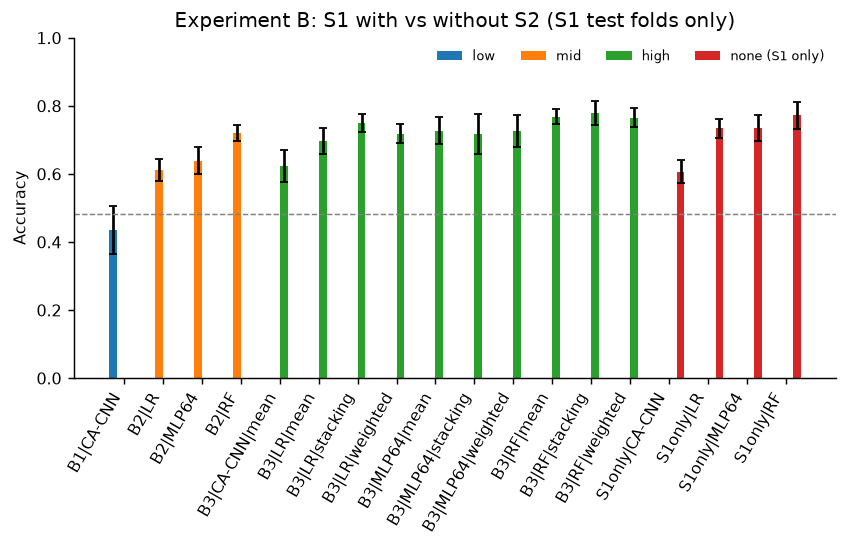

In [3]:
show(F / 'expB_s1_s2_fusion.png', 800)

**Paired comparison with the identical S1-only model** (Wilcoxon over CV repeats):

In [4]:
table(R / 'expB_significance.csv')

,exp,variant,vs,acc,acc_vs,diff,wilcoxon_p
0,expB_b2,B2|LR,S1only|LR,0.612,0.734,-0.122,0.002
1,expB_b2,B2|MLP64,S1only|MLP64,0.640,0.736,-0.097,0.004
2,expB_b2,B2|RF,S1only|RF,0.721,0.772,-0.052,0.008
3,expB_b2,B3|LR|mean,S1only|LR,0.698,0.734,-0.036,0.035
4,expB_b2,B3|LR|stacking,S1only|LR,0.750,0.734,0.016,0.305
5,expB_b2,B3|LR|weighted,S1only|LR,0.719,0.734,-0.016,0.172
6,expB_b2,B3|MLP64|mean,S1only|MLP64,0.728,0.736,-0.009,0.609
7,expB_b2,B3|MLP64|stacking,S1only|MLP64,0.717,0.736,-0.019,0.340
8,expB_b2,B3|MLP64|weighted,S1only|MLP64,0.726,0.736,-0.010,0.438
9,expB_b2,B3|RF|mean,S1only|RF,0.769,0.772,-0.003,0.844


**Secondary check:** does the pooled model still recognise SmellNet substances on the unseen day 6 (50-way)?

In [5]:
table(R / 'expB_s2_secondary_check.csv')

,model,s2_day6_acc_50way
0,LR,0.32
1,RF,0.38
2,MLP64,0.32


## AB8: amount of S2 and each harmonisation step

In [6]:
table(A / 'AB8_s2_gain_by_setting.csv')

,setting,B2|LR,B2|MLP64,B2|RF,S1only|LR,S1only|MLP64,S1only|RF,gain_LR,gain_RF,gain_MLP64
0,diff25,0.650,0.667,0.733,0.662,0.641,0.738,-0.012,-0.005,0.026
1,first_120s,0.621,0.707,0.603,0.679,0.719,0.662,-0.059,-0.059,-0.012
2,first_180s,0.700,0.750,0.667,0.729,0.769,0.693,-0.029,-0.026,-0.019
3,first_60s,0.619,0.591,0.655,0.655,0.633,0.688,-0.036,-0.033,-0.041
4,full,0.612,0.640,0.721,0.734,0.736,0.772,-0.122,-0.052,-0.097
5,no_common_length,0.634,0.660,0.719,0.734,0.736,0.772,-0.100,-0.053,-0.076
6,no_polarity(R),0.498,0.574,0.629,0.734,0.736,0.691,-0.236,-0.062,-0.162
7,norm_none,0.334,0.500,0.684,0.712,0.793,0.778,-0.378,-0.093,-0.293
8,norm_ratio,0.400,0.567,0.679,0.712,0.793,0.778,-0.312,-0.098,-0.226
9,s2_frac_10,0.598,0.655,0.657,0.734,0.736,0.772,-0.136,-0.116,-0.081


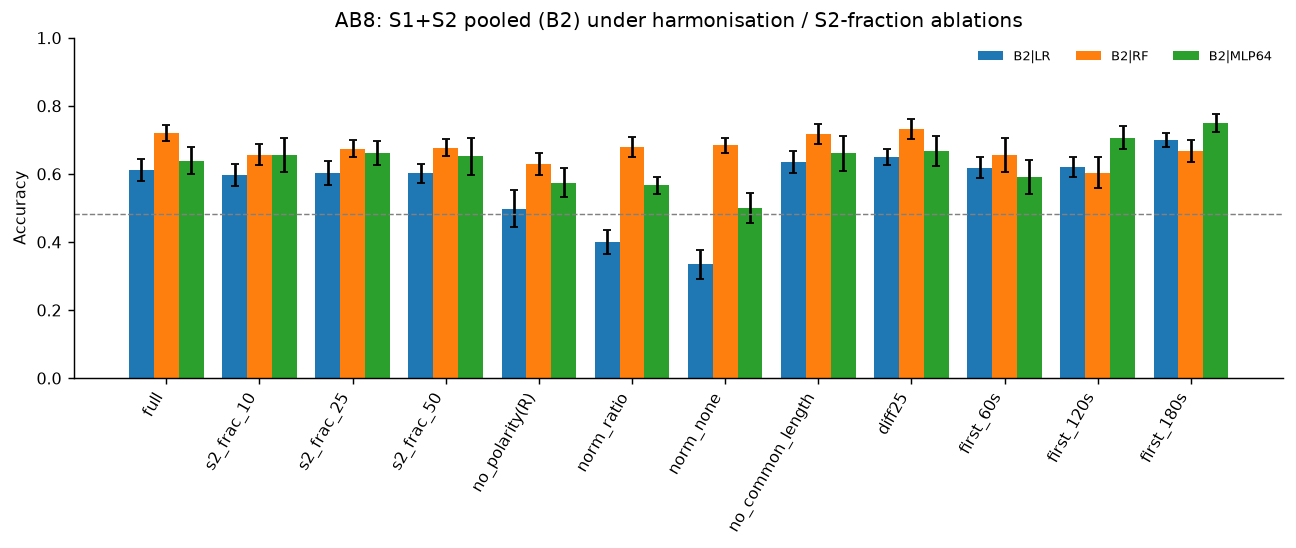

In [7]:
show(F / 'AB8_s2_fusion.png', 900)